# 04 · Padrões de fraude em grafos

**Objetivo:** conhecer os formatos típicos de fraude e lavagem de dinheiro, gerá-los com `pixfraud.patterns`, injetá-los numa rede legítima e verificar quais métricas os denunciam. É um **experimento controlado**: sabemos exatamente onde está a fraude.

**Leitura de apoio:** Altman et al. (2023), que descreve padrões de lavagem em transações sintéticas; Akoglu, Tong e Koutra (2015), um survey de detecção de anomalias em grafos.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.anomaly import isolation_forest
from pixfraud.graph import build_graph, describe
from pixfraud.patterns import PATTERNS, chain, fan_in, fraud_nodes, inject
from pixfraud.simulation import SimulationConfig, generate_dataset
from pixfraud.visualization import draw_graph, plot_heat_graph

## 1. O catálogo

| Padrão | Formato | No Pix |
|---|---|---|
| `fan_in` | muitos → um | várias vítimas pagam a mesma laranja |
| `fan_out` | um → muitos | a laranja pulveriza o valor em várias contas |
| `chain` | a → b → c → … | lavagem em cadeia |
| `cycle` | a → b → … → a | *round-tripping*: o dinheiro volta à origem |
| `scatter_gather` | um → muitos → um | espalha o valor e junta de novo num coletor |
| `mule_ring` | vítimas → laranjas → cadeia → coletor | a quadrilha completa, como no dataset sintético |

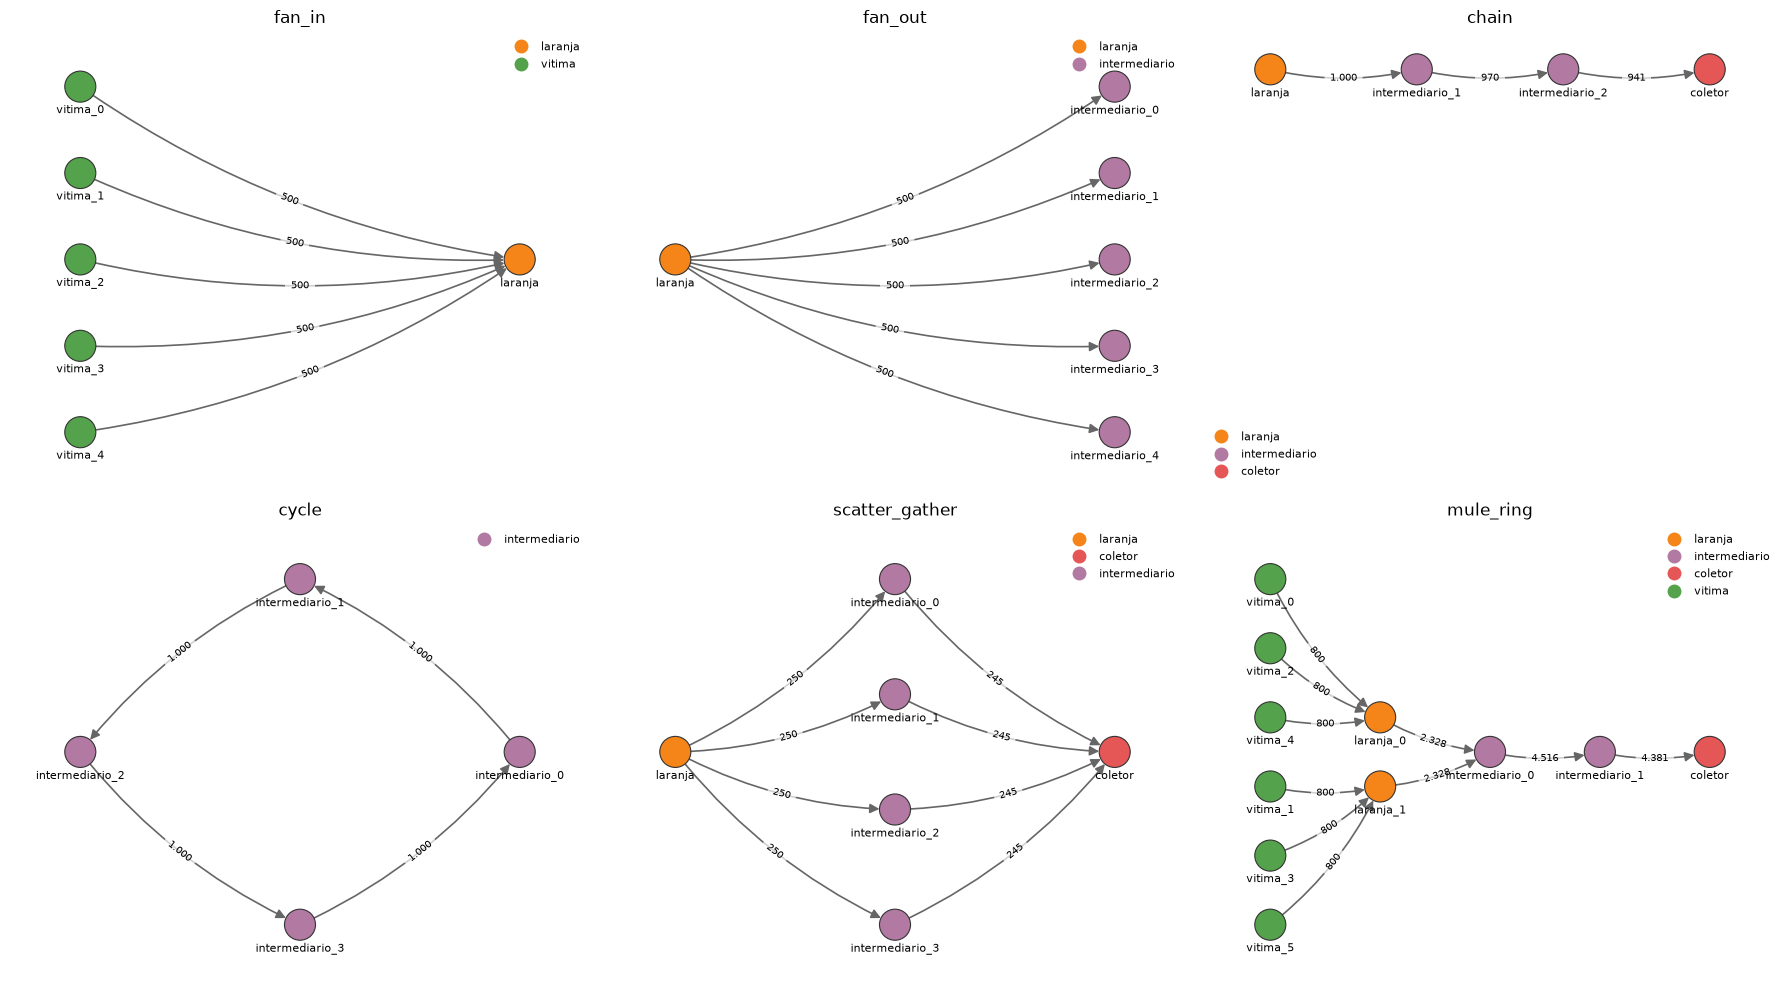

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (nome, criar) in zip(axes.flat, PATTERNS.items()):
    draw_graph(criar(), ax=ax, title=nome)
plt.tight_layout()

Cada função aceita parâmetros: tamanho, valor, comissão retida a cada salto (`fee`)… Veja com `help(chain)`.

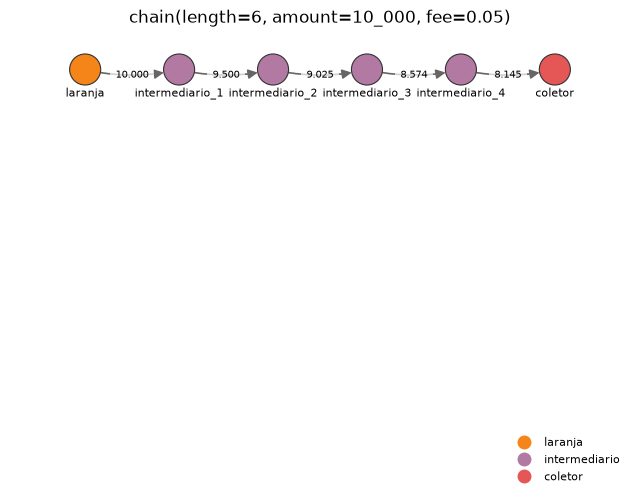

In [3]:
draw_graph(chain(length=6, amount=10_000, fee=0.05), title="chain(length=6, amount=10_000, fee=0.05)");

## 2. Assinaturas estruturais

Dentro de cada padrão isolado, as métricas das contas de fraude já mostram o "formato":

In [4]:
linhas = []
for nome, criar in PATTERNS.items():
    P = criar()
    intermediacao = nx.betweenness_centrality(P)
    for conta, papel in P.nodes(data="role"):
        if papel != "vitima":
            linhas.append({
                "padrão": nome, "conta": conta, "papel": papel,
                "entrada": P.in_degree(conta), "saída": P.out_degree(conta),
                "intermediação": round(intermediacao[conta], 3),
            })
pd.DataFrame(linhas).set_index(["padrão", "conta"])

papel  entrada  saída  intermediação
padrão         conta                                                        
fan_in         laranja                laranja        5      0          0.000
fan_out        laranja                laranja        0      5          0.000
               intermediario_0  intermediario        1      0          0.000
               intermediario_1  intermediario        1      0          0.000
               intermediario_2  intermediario        1      0          0.000
               intermediario_3  intermediario        1      0          0.000
               intermediario_4  intermediario        1      0          0.000
chain          laranja                laranja        0      1          0.000
               intermediario_1  intermediario        1      1          0.333
               intermediario_2  intermediario        1      1          0.333
               coletor                coletor        1      0          0.000
cycle          intermediario_0  intermediario        1      1          0.500
               intermediario_1  intermediario        1      1          0.500
               intermediario_2  intermediario        1      1          0.500
               intermediario_3  intermediario        1      1          0.500
scatter_gather laranja                laranja        0      4          0.000
               coletor                coletor        4      0          0.000
               intermediario_0  intermediario        1      1          0.013
               intermediario_1  intermediario        1      1          0.013
               intermediario_2  intermediario        1      1          0.013
               intermediario_3  intermediario        1      1          0.013
mule_ring      laranja_0              laranja        3      1          0.100
               laranja_1              laranja        3      1          0.100
               intermediario_0  intermediario        2      1          0.178
               intermediario_1  intermediario        1      1          0.100
               coletor                coletor        1      0          0.000

## 3. Experimento: injetar e procurar

1. Gerar uma rede **só com contas legítimas**: o gerador com `n_rings=0`.
2. Injetar um exemplar de cada padrão com `inject`. As vítimas são associadas a contas existentes, e cada conta nova faz alguns Pix de camuflagem para contas existentes, para não ficar isolada.
3. Calcular as métricas e ver em que **percentil** ficam as contas injetadas. Percentil 0,99 significa que a conta está entre as 1% mais extremas naquela métrica.

In [5]:
contas, tx = generate_dataset(SimulationConfig(n_people=800, n_merchants=40, n_rings=0, seed=7))
fundo = build_graph(tx, contas["account_id"])
nx.set_node_attributes(fundo, contas.set_index("account_id")["role"].to_dict(), "role")

G = fundo
for i, (nome, criar) in enumerate(PATTERNS.items()):
    G = inject(G, criar(), prefix=nome, seed=i)

injetadas = fraud_nodes(G)
print(len(injetadas), "contas de fraude injetadas em uma rede de", fundo.number_of_nodes(), "contas")
describe(G)

26 contas de fraude injetadas em uma rede de 840 contas


vértices                                866
arestas                               12433
direcionado                            True
multigrafo                            False
densidade                          0.016597
grau médio                        28.713626
laços                                     0
componentes fracamente conexas            1
componentes fortemente conexas           56
reciprocidade                      0.172123
acíclico (DAG)                        False
dtype: object

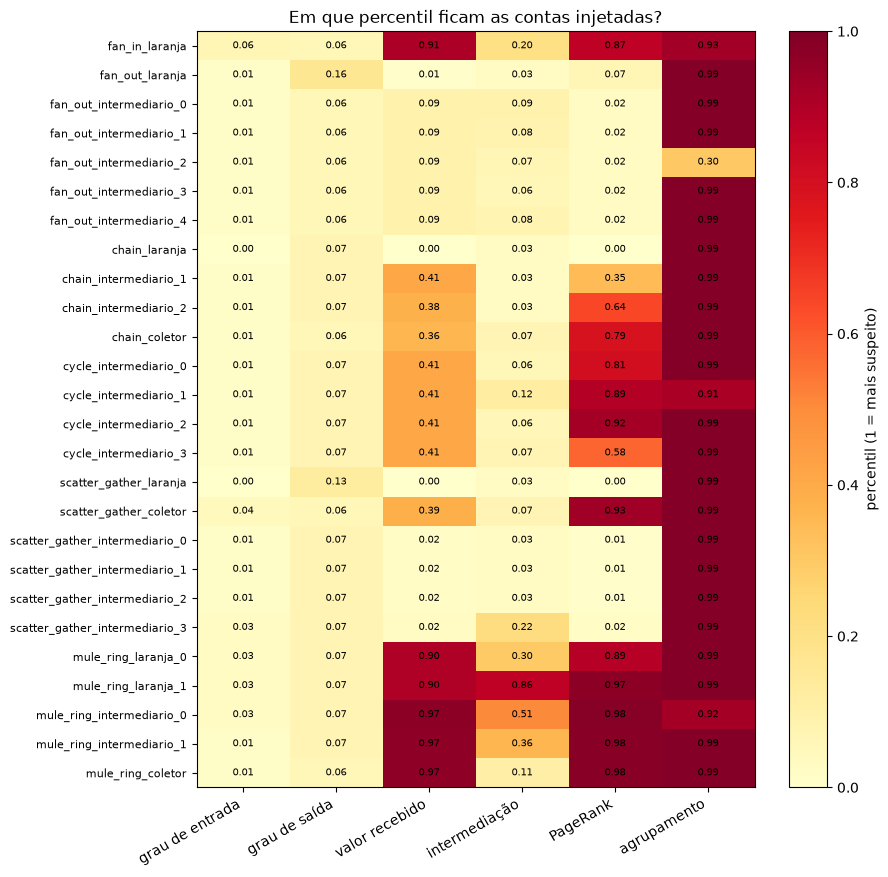

In [6]:
metricas = pd.DataFrame({
    "grau de entrada": pd.Series(dict(G.in_degree())),
    "grau de saída": pd.Series(dict(G.out_degree())),
    "valor recebido": pd.Series(dict(G.in_degree(weight="amount"))),
    "intermediação": pd.Series(nx.betweenness_centrality(G, k=300, seed=0)),
    "PageRank": pd.Series(nx.pagerank(G, weight="amount")),
    "agrupamento": pd.Series(nx.clustering(G.to_undirected())),
})
percentis = metricas.rank(pct=True)
# No agrupamento, o suspeito é o valor BAIXO: invertemos para que "quente" signifique suspeito.
percentis["agrupamento"] = 1 - percentis["agrupamento"]

tabela = percentis.loc[injetadas]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(tabela) + 1.5))
imagem = ax.imshow(tabela.to_numpy(), cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(tabela.shape[1]), tabela.columns, rotation=30, ha="right")
ax.set_yticks(range(len(tabela)), tabela.index, fontsize=8)
for (i, j), valor in np.ndenumerate(tabela.to_numpy()):
    ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagem, ax=ax, label="percentil (1 = mais suspeito)")
ax.set_title("Em que percentil ficam as contas injetadas?");

**Para pensar:**

- Quais padrões se destacam no valor recebido e no PageRank? E no agrupamento?
- Repare na coluna do grau: as contas injetadas estão no percentil ~0,01, ou seja, são extremas **para baixo**. Isso é suspeito ou normal?
- Algum padrão fica "morno" em quase tudo? Por quê?
- O ciclo é fácil de ver nessas métricas? (Pista: a seção 5.)

## 4. Três detectores

Como aqui conhecemos a resposta, dá para medir a **precision@k**: das $k$ contas mais suspeitas ($k$ = nº de contas injetadas), quantas são de fato fraude? Três candidatos:

1. **Média dos percentis**: suspeito é quem tem valores altos em tudo;
2. **Extremidade**: suspeito é quem está longe da mediana, *para cima ou para baixo*: $|p - 0{,}5| \cdot 2$, com a média entre as métricas;
3. **Isolation Forest**, que procura combinações raras de valores (`pixfraud.anomaly`).

In [7]:
alvo = pd.Series(False, index=list(G.nodes))
alvo[injetadas] = True
k = int(alvo.sum())

detectores = {
    "média dos percentis": percentis.mean(axis=1),
    "extremidade": ((percentis - 0.5).abs() * 2).mean(axis=1),
    "Isolation Forest": isolation_forest(metricas).scores,
}
for nome, risco in detectores.items():
    print(f"{nome:20} precision@{k} = {alvo[risco.nlargest(k).index].mean():.2f}")

média dos percentis  precision@26 = 0.00
extremidade          precision@26 = 0.19
Isolation Forest     precision@26 = 0.35


A média dos percentis falha porque as contas de fraude **não são grandes**: fazem poucos Pix, então têm grau baixo. O que as torna estranhas é a *combinação*: grau baixo com valor recebido alto, PageRank alto e nenhum triângulo. **Anomalia tem dois lados**, e os detectores precisam enxergar os dois.

Cuidado ao comemorar: parte desse sucesso vem de uma característica do gerador. Todas as contas legítimas são bem ativas, então qualquer conta com poucos Pix já se destaca. O exercício 4 explora isso.

O grafo de calor do Isolation Forest mostra onde ele acerta (contorno preto) e onde erra:

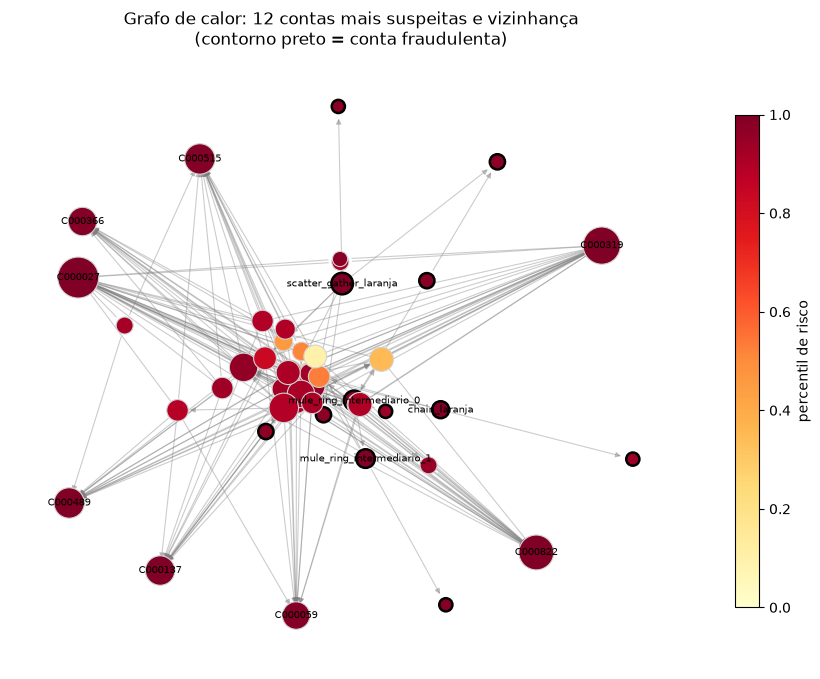

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
plot_heat_graph(G, detectores["Isolation Forest"], top_k=12, fraud=alvo, ax=ax);

## 5. Procurando padrões pela estrutura

Alguns padrões têm uma assinatura exata em teoria dos grafos e podem ser procurados diretamente, sem aprendizado de máquina. O ciclo, por exemplo, forma uma **componente fortemente conexa** pequena: o dinheiro circula entre poucas contas e nunca volta da rede para elas.

In [9]:
tamanhos = pd.Series([len(c) for c in nx.strongly_connected_components(G)]).value_counts().sort_index()
print("tamanho das CFCs -> quantidade:\n", tamanhos.to_string(), sep="")

pequenas = [sorted(c) for c in nx.strongly_connected_components(G) if 1 < len(c) < 20]
pequenas

tamanho das CFCs -> quantidade:
1      54
4       1
808     1


[['cycle_intermediario_0',
  'cycle_intermediario_1',
  'cycle_intermediario_2',
  'cycle_intermediario_3']]

Numa rede real, ciclos legítimos também existem (amigos acertando contas). A pergunta de pesquisa passa a ser quais ciclos são suspeitos: valores altos, contas novas, curto intervalo de tempo…

## Exercícios

1. **Novo padrão.** Crie o padrão *gather-scatter* (vítimas → laranja → vários intermediários) combinando `fan_in` e `fan_out` com `nx.compose`, e desenhe-o. Dica: os dois chamam a conta central de `"laranja"`, então ela é unida automaticamente.
2. **Sem camuflagem.** Repita a injeção com `camouflage=0`. O que acontece com as componentes fracamente conexas (`describe`)? Por que a camuflagem deixa o experimento mais realista?
3. **Tamanho da cadeia.** Injete quadrilhas (`mule_ring`) com cadeias de 1, 3 e 6 intermediários, cada uma em uma cópia separada da rede de fundo. Compare o percentil de intermediação (exata) de cada intermediário. O que acontece à medida que a cadeia cresce? Por que o primeiro intermediário tem intermediação maior que o último?
4. **Sutileza.** Injete um `fan_in` com só 2 vítimas pagando R$ 50 cada e veja em que posição do ranking do Isolation Forest a laranja fica. Compare com o `fan_in` padrão. O resultado é o que você esperava? O que ele revela sobre a rede de fundo?

In [10]:
# seu código aqui